<a href="https://colab.research.google.com/github/Muqtarali/fine_tuning_llm/blob/main/Domain-Specific%20FineTuning/LLM_Fine_Tuning__Train_LLMs_on_Your_PDF_Text_Data_Domain_Specific_Fine_Tuning_with_HuggingFace.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -U  transformers peft bitsandbytes accelerate AutoModelForCausalLM

ERROR: Could not find a version that satisfies the requirement AutoModelForCausalLM (from versions: none)
ERROR: No matching distribution found for AutoModelForCausalLM


In [ ]:
!pip install trl

In [ ]:
!pip install PyMuPDF

Prebuilt data from huggingface data hub

In [ ]:

from datasets import Dataset, load_dataset

In [ ]:
dataset = load_dataset("roneneldan/TinyStories", split="train")


In [ ]:
print(dataset)

Dataset({
    features: ['text'],
    num_rows: 2119719
})


In [ ]:
print(dataset[0])

{'text': 'One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.\n\nLily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."\n\nTogether, they shared the needle and sewed the button on Lily\'s shirt. It was not difficult for them because they were sharing and helping each other. After they finished, Lily thanked her mom for sharing the needle and fixing her shirt. They both felt happy because they had shared and worked together.'}



Our own custom data (non instrcution data) for domain specific finetuning

In [ ]:
!pip install pypdf

In [ ]:
import fitz

In [ ]:
#data ko read kar rha ha pdf se

def extract_text_from_pdf(pdf_path):
    text_blocks = []
    with fitz.open(pdf_path) as doc:
        for page in doc:
            text = page.get_text("text").strip()
            if text:
                text_blocks.append(text)
    return text_blocks

In [ ]:


pdf_texts = extract_text_from_pdf("/content/Metformin.pdf")

In [ ]:
pdf_texts

['Metformin is one of the most widely prescribed oral antihyperglycemic agents.\u200b\n Its primary mechanism of action involves the activation of AMP-activated protein kinase \n(AMPK), a central metabolic regulator that promotes glucose uptake and fatty acid oxidation \nwhile inhibiting hepatic gluconeogenesis.\u200b\n Beyond its glycemic control, Metformin has been shown to improve cardiovascular outcomes \nand display anti-inflammatory properties.\u200b\n Recent studies also suggest potential anticancer effects through inhibition of the mTOR \nsignaling pathway and suppression of tumor angiogenesis. \n \nClinical trials have demonstrated that combining Atorvastatin with Ezetimibe results in \nsignificant reductions in low-density lipoprotein cholesterol (LDL-C) levels compared to \nmonotherapy.\u200b\n Ezetimibe acts by inhibiting the Niemann–Pick C1-like 1 (NPC1L1) transporter in the intestinal \nwall, reducing cholesterol absorption, while Atorvastatin inhibits hepatic HMG-CoA red

| Model                        | Max Context Window (chunk length) during training | Approx words     | Comment                                                            |
| ---------------------------- | ------------------------------------------------- | ---------------- | ------------------------------------------------------------------ |
| **GPT-1 (2018)**             | 512 tokens                                        | ~350 words       | First transformer LM, small context                                |
| **GPT-2 (2019)**             | 1,024 tokens                                      | ~750 words       | Larger context for smoother coherence                              |
| **GPT-3 (2020)**             | 2,048 tokens                                      | ~1.5k words      | Trained on 300 B tokens with this window                           |
| **GPT-3.5 / ChatGPT (2022)** | 4,096 tokens                                      | ~3k words        | Used mixture of 2k–4k during pretraining + instruction fine-tuning |
| **GPT-4 (2023)**             | 8,192 – 32,768 – 1,28,000 tokens*                            | up to ~25k to 1L words | Multi-context variants (8k & 32k models)                           |


| Step                                     | What Happens                                                                             | Example                                     |
| ---------------------------------------- | ---------------------------------------------------------------------------------------- | ------------------------------------------- |
| **1️⃣ Data Collection**                  | Crawl text from web (Wikipedia, CommonCrawl, Books, PubMed, Code, etc.)                  | Billions of documents                       |
| **2️⃣ Cleaning / Filtering**             | Remove HTML, junk, duplicates, low-quality content                                       | Similar to your `strip()` & len filter      |
| **3️⃣ Splitting / Chunking**             | Split into paragraphs / segments using regex rules, sentence boundaries, or token length | Like your `re.split(r'\n\s*\n')`            |
| **4️⃣ Tokenization**                     | Convert text chunks → token IDs using BPE                                                | “The cat” → `[1012, 52, 199]`               |
| **5️⃣ Training (Next-Token Prediction)** | Model learns to predict the next token in each chunk                                     | Input: “The cat sat on the” → Target: “mat” |


In [ ]:
import re
def split_paragraphs(pages):
    paragraphs = []
    for page_text in pages:
        # Split on double line breaks or long newlines
        chunks = re.split(r'\n\s*\n', page_text)
        for chunk in chunks:
            clean = chunk.strip()
            if len(clean) > 30:  # ignore too short lines
                paragraphs.append(clean)
    return paragraphs


In [ ]:
paragraphs = split_paragraphs(pdf_texts)

In [ ]:

data = [{"text": p} for p in paragraphs]

In [ ]:

data

[{'text': 'Metformin is one of the most widely prescribed oral antihyperglycemic agents.\u200b\n Its primary mechanism of action involves the activation of AMP-activated protein kinase \n(AMPK), a central metabolic regulator that promotes glucose uptake and fatty acid oxidation \nwhile inhibiting hepatic gluconeogenesis.\u200b\n Beyond its glycemic control, Metformin has been shown to improve cardiovascular outcomes \nand display anti-inflammatory properties.\u200b\n Recent studies also suggest potential anticancer effects through inhibition of the mTOR \nsignaling pathway and suppression of tumor angiogenesis.'},
 {'text': 'Clinical trials have demonstrated that combining Atorvastatin with Ezetimibe results in \nsignificant reductions in low-density lipoprotein cholesterol (LDL-C) levels compared to \nmonotherapy.\u200b\n Ezetimibe acts by inhibiting the Niemann–Pick C1-like 1 (NPC1L1) transporter in the intestinal \nwall, reducing cholesterol absorption, while Atorvastatin inhibits h

In [ ]:
#data to hugging phase compatable

dataset=Dataset.from_list(data)


In [ ]:
dataset

Dataset({
    features: ['text'],
    num_rows: 4
})

Select model

In [ ]:

# model_name = "meta-llama/Llama-2-7b-hf"
# model_name = "meta-llama/Llama-3.1-8B"
model_name = "TinyLlama/TinyLlama-1.1B-intermediate-step-1431k-3T"

In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM, Trainer, TrainingArguments, DataCollatorForLanguageModeling


In [ ]:


tokenizer = AutoTokenizer.from_pretrained(model_name)

In [ ]:
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

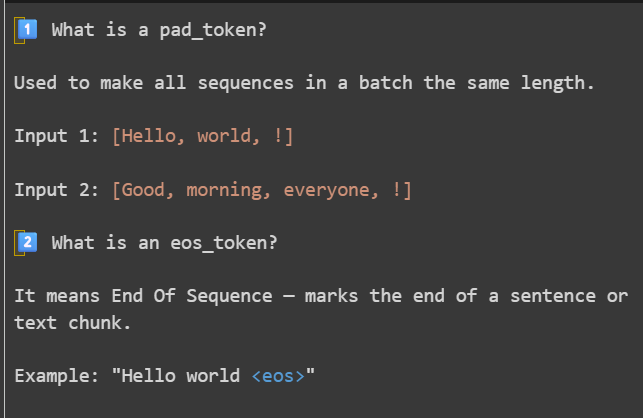

In [ ]:

def tokenize_fn(examples):
    tokens = tokenizer(examples["text"],truncation=True,padding="max_length",max_length=512)
    tokens["labels"] = tokens["input_ids"].copy()
    return tokens

1️⃣ Input

examples["text"]
→ This comes from your dataset, like:

{"text": "Metformin improves insulin sensitivity in the liver."}


2️⃣ Tokenization
tokens = tokenizer(examples["text"], truncation=True, padding="max_length", max_length=512)

| Argument               | Meaning                                                                              |
| ---------------------- | ------------------------------------------------------------------------------------ |
| `truncation=True`      | If the text is longer than 512 tokens, cut it off (keep only first 512).             |
| `padding="max_length"` | If the text is shorter than 512 tokens, pad it with `<pad>` tokens up to 512 length. |
| `max_length=512`       | Fixed sequence length per training example (standard size).                          |

{
  'input_ids': [1, 4382, 272, 98, ... , 2, 2, 2],
  'attention_mask': [1, 1, 1, ... , 0, 0, 0]
}

3️⃣ Labels

tokens["labels"] = tokens["input_ids"].copy()

This is the key step for causal (unsupervised) language modeling.

It means: “The model should try to predict the next token of this same sequence.”

Example:
| Input Tokens                 | Target Labels (Shifted Internally) |
| ---------------------------- | ---------------------------------- |
| `Metformin improves insulin` | `improves insulin sensitivity`     |

So model learns:

“Given previous words, predict the next word.”

That’s how GPT-style unsupervised training works — no Q/A, no instruction, just next-token prediction.

4️⃣ Output Returned

The final dictionary returned looks like this:

{

  "input_ids": [...],

  "attention_mask": [...],
  
  "labels": [...]

}

In [ ]:
tokenized = dataset.map(tokenize_fn, batched=True, remove_columns=["text"])


Map:   0%|          | 0/4 [00:00<?, ? examples/s]

In [ ]:
tokenized

Dataset({
    features: ['input_ids', 'attention_mask', 'labels'],
    num_rows: 4
})

In [ ]:
from transformers import Trainer, TrainingArguments,AutoModelForCausalLM

In [ ]:
model=AutoModelForCausalLM.from_pretrained(model_name)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

| Parameter                       | Purpose                | Typical Range | Effect                      |
| ------------------------------- | ---------------------- | ------------- | --------------------------- |
| **output_dir**                  | Save model/checkpoints | Folder path   | Where your model ends up    |
| **overwrite_output_dir**        | Allow overwrite        | True / False  | Avoids folder conflicts     |
| **num_train_epochs**            | Training cycles        | 1–5           | More = longer training      |
| **per_device_train_batch_size** | Batch per GPU          | 1–8 (Colab)   | Affects speed & memory      |
| **save_steps**                  | Save frequency         | 100–1000      | More = frequent checkpoints |
| **save_total_limit**            | Keep last N            | 1–3           | Saves disk                  |
| **logging_steps**               | Log every X steps      | 20–100        | For progress monitoring     |
| **learning_rate**               | Weight update rate     | 1e-5–5e-5     | Controls stability          |
| **fp16**                        | Mixed precision        | True          | Faster + less memory        |
| **report_to**                   | Logging destination    | "none"        | Keeps it simple             |


In [ ]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./llama-pharma-domain",
    num_train_epochs=2,
    per_device_train_batch_size=2,
    save_steps=500,
    save_total_limit=2,
    logging_steps=50,
    learning_rate=2e-5,
    fp16=True,
    report_to="none"
)

In [ ]:

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized
)


OutOfMemoryError: CUDA out of memory. Tried to allocate 250.00 MiB. GPU 0 has a total capacity of 14.56 GiB of which 1.81 MiB is free. Including non-PyTorch memory, this process has 14.56 GiB memory in use. Of the allocated memory 14.28 GiB is allocated by PyTorch, and 146.98 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

In [ ]:
trainer.train()

OutOfMemoryError: CUDA out of memory. Tried to allocate 22.00 MiB. GPU 0 has a total capacity of 14.56 GiB of which 9.81 MiB is free. Including non-PyTorch memory, this process has 14.55 GiB memory in use. Of the allocated memory 14.39 GiB is allocated by PyTorch, and 26.64 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

**Here we are not specfiying anything means this is full fine-tuning**

Now we have two methods for Partial Finetuning **bold text**


1.   Feerze some layer and finetune unfreeze layer(old CNN and Bert sytel method)
2.   LORA(Append some external weight to the already trained pretrain weight)



First Lets's see the method where we are going to freeze the layer

In [ ]:

# # -------------------------------------------------------------
# # 1️⃣ Install dependencies
# # -------------------------------------------------------------
# !pip install -q transformers datasets accelerate bitsandbytes

# # -------------------------------------------------------------
# # 2️⃣ Imports
# # -------------------------------------------------------------
# import torch
# from transformers import AutoTokenizer, AutoModelForCausalLM, Trainer, TrainingArguments, DataCollatorForLanguageModeling
# from datasets import load_dataset
# import os, re

# # -------------------------------------------------------------
# # 3️⃣ Load base model and tokenizer
# # -------------------------------------------------------------
# model_name = "TinyLlama/TinyLlama-1.1B-intermediate-step-1431k-3T"
# tokenizer = AutoTokenizer.from_pretrained(model_name)
# model = AutoModelForCausalLM.from_pretrained(model_name, device_map="auto")

# # -------------------------------------------------------------
# # 4️⃣ Freeze everything
# # -------------------------------------------------------------
# for param in model.parameters():
#     param.requires_grad = False

# # -------------------------------------------------------------
# # 5️⃣ Unfreeze last 4 transformer blocks + lm_head
# # -------------------------------------------------------------
# for name, param in model.named_parameters():
#     if any(f"layers.{i}." in name for i in range(20, 24)):  # last 4 layers
#         param.requires_grad = True
#     if "lm_head" in name:
#         param.requires_grad = True

# # Verify how many parameters are trainable
# trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
# total = sum(p.numel() for p in model.parameters())
# print(f"✅ Trainable: {trainable/total*100:.2f}% of total parameters")

# # -------------------------------------------------------------
# # 6️⃣ Load your dataset
# # -------------------------------------------------------------
# dataset = load_dataset("json", data_files={"train": "pharma_non_instruction.jsonl"})

# def tokenize_fn(examples):
#     tokens = tokenizer(
#         examples["text"],
#         truncation=True,
#         padding="max_length",
#         max_length=512
#     )
#     tokens["labels"] = tokens["input_ids"].copy()
#     return tokens

# tokenized = dataset["train"].map(tokenize_fn, batched=True, remove_columns=["text"])

# # -------------------------------------------------------------
# # 7️⃣ Data collator for causal LM
# # -------------------------------------------------------------
# data_collator = DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm=False)

# # -------------------------------------------------------------
# # 8️⃣ Training arguments
# # -------------------------------------------------------------
# os.environ["WANDB_DISABLED"] = "true"  # disable wandb
# training_args = TrainingArguments(
#     output_dir="./tinyllama-pharma-last4",
#     overwrite_output_dir=True,
#     num_train_epochs=2,
#     per_device_train_batch_size=2,
#     gradient_accumulation_steps=4,
#     learning_rate=1e-4,        # slightly higher since fewer params
#     fp16=True,
#     logging_steps=20,
#     save_steps=200,
#     save_total_limit=2,
#     report_to="none"
# )

# # -------------------------------------------------------------
# # 9️⃣ Trainer setup
# # -------------------------------------------------------------
# trainer = Trainer(
#     model=model,
#     args=training_args,
#     train_dataset=tokenized,
#     data_collator=data_collator
# )

# # -------------------------------------------------------------
# # 🔟 Start training
# # -------------------------------------------------------------
# trainer.train()

# # -------------------------------------------------------------
# # 11️⃣ Save final model
# # -------------------------------------------------------------
# trainer.save_model("./tinyllama-pharma-last4-final")
# print("\n✅ Training completed and model saved!")


Now lets see the LORA based method

In [ ]:

import torch, gc
gc.collect()
torch.cuda.empty_cache()

In [ ]:

from transformers import AutoTokenizer, AutoModelForCausalLM, TrainingArguments, Trainer
from peft import LoraConfig, get_peft_model, TaskType
from datasets import load_dataset

In [ ]:
!pip install -U peft bitsandbytes transformers accelerate

In [ ]:


model = "TinyLlama/TinyLlama-1.1B-intermediate-step-1431k-3T"

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(model)

In [ ]:
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token



In [ ]:
def tokenize_fn(examples):
    tokens = tokenizer(
        examples["text"],
        truncation=True,
        padding="max_length",
        max_length=512
    )
    tokens["labels"] = tokens["input_ids"].copy()
    return tokens

In [ ]:

tokenized = dataset.map(tokenize_fn, batched=True)

Map:   0%|          | 0/4 [00:00<?, ? examples/s]

In [ ]:
import gc
import torch

del model
gc.collect()
torch.cuda.empty_cache()

In [ ]:
from transformers import AutoModelForCausalLM, BitsAndBytesConfig

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True
)

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    quantization_config=bnb_config,
    device_map="auto"
)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

In [ ]:
lora_config = LoraConfig(
    task_type=TaskType.CAUSAL_LM,
    r=8,
    lora_alpha=16,
    target_modules=["q_proj","v_proj"],
    lora_dropout=0.05,
    bias="none"
)


In [ ]:
help(LoraConfig)

Help on class LoraConfig in module peft.tuners.lora.config:

class LoraConfig(peft.config.PeftConfig)
 |  LoraConfig(
 |      task_type: 'Optional[Union[str, TaskType]]' = None,
 |      peft_type: 'Optional[Union[str, PeftType]]' = None,
 |      auto_mapping: 'Optional[dict]' = None,
 |      peft_version: 'Optional[str]' = None,
 |      base_model_name_or_path: 'Optional[str]' = None,
 |      revision: 'Optional[str]' = None,
 |      inference_mode: 'bool' = False,
 |      r: 'int' = 8,
 |      target_modules: 'Optional[Union[list[str], str]]' = None,
 |      exclude_modules: 'Optional[Union[list[str], str]]' = None,
 |      lora_alpha: 'int' = 8,
 |      lora_dropout: 'float' = 0.0,
 |      fan_in_fan_out: 'bool' = False,
 |      bias: "Literal['none', 'all', 'lora_only']" = 'none',
 |      use_rslora: 'bool' = False,
 |      modules_to_save: 'Optional[list[str]]' = None,
 |      init_lora_weights: "bool | Literal['gaussian', 'eva', 'olora', 'pissa', 'pissa_niter_[number of iters]', '

In [ ]:

# save adapter
non_inst_model_lora = get_peft_model(model, lora_config)

In [ ]:
args = TrainingArguments(
    output_dir="./tinyllama-lora",
    num_train_epochs=5,
    per_device_train_batch_size=1,
    gradient_accumulation_steps=8,
    learning_rate=2e-4,
    fp16=True,
    logging_steps=20,
    save_total_limit=1,
    report_to="none"
)

In [ ]:
trainer = Trainer(
    model=non_inst_model_lora,
    args=args,
    train_dataset=tokenized
)

In [ ]:

trainer.train()

Step,Training Loss


TrainOutput(global_step=5, training_loss=9.303196716308594, metrics={'train_runtime': 7.1374, 'train_samples_per_second': 2.802, 'train_steps_per_second': 0.701, 'total_flos': 63629646888960.0, 'train_loss': 9.303196716308594, 'epoch': 5.0})

In [ ]:
model_path='/content/tinyllama-lora/checkpoint-5'

In [ ]:
model = AutoModelForCausalLM.from_pretrained(model_path, device_map="auto")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/88 [00:00<?, ?it/s]

In [ ]:
prompt = "Clinical trials demonstrated that combining Atorvastatin with Ezetimibe"

In [ ]:
inputs = tokenizer(prompt, return_tensors="pt")

inputs = {
    k: v.to(model.device)
    for k, v in inputs.items()
}

outputs = model.generate(
    **inputs,
    max_new_tokens=100
)

[transformers] Both `max_new_tokens` (=100) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


In [ ]:


print("\nModel Output:\n")
print(tokenizer.decode(outputs[0], skip_special_tokens=True))


Model Output:

Clinical trials demonstrated that combining Atorvastatin with Ezetimibe was more effective than Atorvastatin alone in reducing LDL-C levels.
The safety and efficacy of Atorvastatin 80 mg once daily in combination with Ezetimibe 10 mg once daily in patients with type 2 diabetes mellitus (T2DM) were evaluated in a 24-week, double-blind, randomized, placebo-controlled, parallel-group, multicenter


Non-Instruction Finetuning **Dataset**

In [ ]:

dataset = load_dataset("HuggingFaceFW/fineweb")
pubmed = load_dataset("ncbi/pubmed")
dataset = load_dataset("datajuicer/the-pile-pubmed-abstracts-refined-by-data-juicer")
dataset = load_dataset("open-llm-leaderboard/open_llm_corpus")
owt = load_dataset("Skylion007/openwebtext")
ds = load_dataset("armanc/scientific_papers")

Instruction Finetuning **Dataset**

In [ ]:
https://huggingface.co/datasets/Amod/mental_health_counseling_conversations
https://huggingface.co/datasets/yahma/alpaca-cleaned
https://huggingface.co/datasets/Open-Orca/OpenOrca
https://huggingface.co/datasets/tatsu-lab/alpaca
https://huggingface.co/datasets/OpenAssistant/oasst1


Prefrence Alignemnt tuing **dataset**

In [ ]:


https://huggingface.co/datasets/Anthropic/hh-rlhf
https://huggingface.co/datasets/argilla/ultrafeedback-binarized-preferences-cleaned
https://huggingface.co/datasets/xinlai/Math-Step-DPO-10K